# Q1: ปริมาณการเดินทางวันทำงาน vs วันหยุดสุดสัปดาห์
**กลุ่ม:** Loading Brain... 1%

**คำถาม:** การเดินทางในวันทำงานกับวันหยุดสุดสัปดาห์ต่างกันอย่างไร เมื่อดูตามวันในสัปดาห์และตามเดือน

**ขอบเขต**
- ใช้ปี 2568 (2025) เท่านั้น เพราะครบ 365 วันและครบ 12 เดือน
- ตัด 3 บริการ: รถร่วม (หมวด 1) ไม่มีข้อมูล และรถ 4 ล้อ 2 รายการ ซึ่งเป็นส่วนหนึ่งของรถทุกประเภท (นับซ้ำ)
- ใช้มัธยฐาน เพราะยังมี outlier ที่ยังยืนยันไม่ได้ (AIE314 บทที่ 5 หน้า 24)
- ไม่บวกปริมาณข้ามบริการ เทียบด้วยอัตราส่วนที่ไม่มีหน่วย จึงไม่รวมคนกับคัน

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.family"] = "Tahoma"

df = pd.read_csv("../outputs/prepared_daily.csv")
df["date"] = pd.to_datetime(df["date"], format= "%Y-%m-%d")

In [2]:
# ปี 2025 เท่านั้น และตัด 3 บริการ
exclude = ["รถร่วม (หมวด 1)", "รถยนต์เฉพาะ 4 ล้อ (ทางด่วน)", "รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ)"]
df_q1 = df[(df["year"] == 2025) & ~df["ยานพาหนะ/ท่า"].isin(exclude)]

print("ขนาด: ", df_q1.shape, "| บริการ: ", df_q1["ยานพาหนะ/ท่า"].nunique(),
      "| qty มีค่า: ", df_q1["qty"].notna().sum())

ขนาด:  (14600, 18) | บริการ:  40 | qty มีค่า:  14244


## 1.1 weekend_ratio และกลุ่มรูปแบบ

weekend_ratio = มัธยฐานวันหยุด ÷ มัธยฐานวันทำงาน (ของบริการนั้น)
- < 1 = วันทำงานคนมากกว่า, > 1 = วันหยุดคนมากกว่า
- จัดกลุ่มด้วย pd.cut: ≤ 0.9 "วันทำงานสูงกว่า", 0.9–1.1 "ใกล้เคียงกัน", > 1.1 "วันหยุดสูงกว่า" (ต่างกันเกิน 10%) (AIE314 บทที่ 6 หน้า 27–30, AIE315 W7 สไลด์ 17)

ตัวอย่างคิดมือ: BTS = 546,383.5 ÷ 813,475 = 0.672 → วันหยุดคนน้อยกว่าวันทำงาน 33%

In [3]:
# ปี 2025, หน่วยคน และตัด 3 บริการที่ข้อมูลไม่ครบทั้งปี
exclude = ["รถร่วม (หมวด 1)", "รถหมวด 3", "รถหมวด 4"]
df_q1 = df[(df["year"] == 2025) & (df["หน่วย"] == "คน") & ~df["ยานพาหนะ/ท่า"].isin(exclude)].copy()

# ป้ายประเภทวันภาษาไทย ไว้ใช้ในกราฟ
df_q1["day_type"] = df_q1["is_weekend"].map({0: "วันธรรมดา", 1: "วันหยุดสุดสัปดาห์"})

print("ขนาด: ", df_q1.shape, "| บริการ: ", df_q1["ยานพาหนะ/ท่า"].nunique())
display(df_q1.groupby("วัตถุประสงค์")["ยานพาหนะ/ท่า"].nunique())

order = ["การเดินทางภายในจังหวัด/กรุงเทพ", "การเดินทางระหว่างจังหวัด", "การเดินทางระหว่างประเทศ"]

ขนาด:  (13140, 19) | บริการ:  36


วัตถุประสงค์
การเดินทางภายในจังหวัด/กรุงเทพ    14
การเดินทางระหว่างจังหวัด           8
การเดินทางระหว่างประเทศ           14
Name: ยานพาหนะ/ท่า, dtype: int64

In [4]:
# 1) ค่าเฉลี่ยต่อวันของแต่ละบริการ แยกประเภทวัน
svc = df_q1.groupby(["วัตถุประสงค์", "ยานพาหนะ/ท่า", "day_type"], as_index= False).agg(
    avg_daily= ("qty", "mean"))

# 2) รวมเป็นยอดของกลุ่ม
purpose = svc.groupby(["วัตถุประสงค์", "day_type"], as_index= False).agg(
    avg_daily= ("avg_daily", "sum"))

# 3) % ต่าง: avg_daily_x = วันธรรมดา, avg_daily_y = วันหยุด
wd = purpose[purpose["day_type"] == "วันธรรมดา"][["วัตถุประสงค์", "avg_daily"]]
we = purpose[purpose["day_type"] == "วันหยุดสุดสัปดาห์"][["วัตถุประสงค์", "avg_daily"]]
diff = pd.merge(wd, we, on= "วัตถุประสงค์", how= "inner", validate= "one_to_one")
diff["pct_diff"] = (diff["avg_daily_y"] - diff["avg_daily_x"]) / diff["avg_daily_x"] * 100
display(diff.round(1))

,วัตถุประสงค์,avg_daily_x,avg_daily_y,pct_diff
0,การเดินทางภายในจังหวัด/กรุงเทพ,2678544.3,1967730.3,-26.5
1,การเดินทางระหว่างจังหวัด,252937.7,263219.3,4.1
2,การเดินทางระหว่างประเทศ,203985.2,215085.0,5.4


In [5]:
# จำนวนบริการแต่ละกลุ่ม
display(ratio["pattern"].value_counts())

# ต่ำสุด 3, สูงสุด 3 และบริการหลักที่จะยกตัวอย่าง
display(ratio.head(3).round(3))
display(ratio.tail(3).round(3))
examples = ["รถไฟฟ้า BTS", "รถเมล์ ขสมก.", "รถยนต์ทุกประเภท (ทางด่วน)", "ท่าอากาศยานสุวรรณภูมิ"]
display(ratio[ratio["ยานพาหนะ/ท่า"].isin(examples)].round(3))

NameError: name 'ratio' is not defined

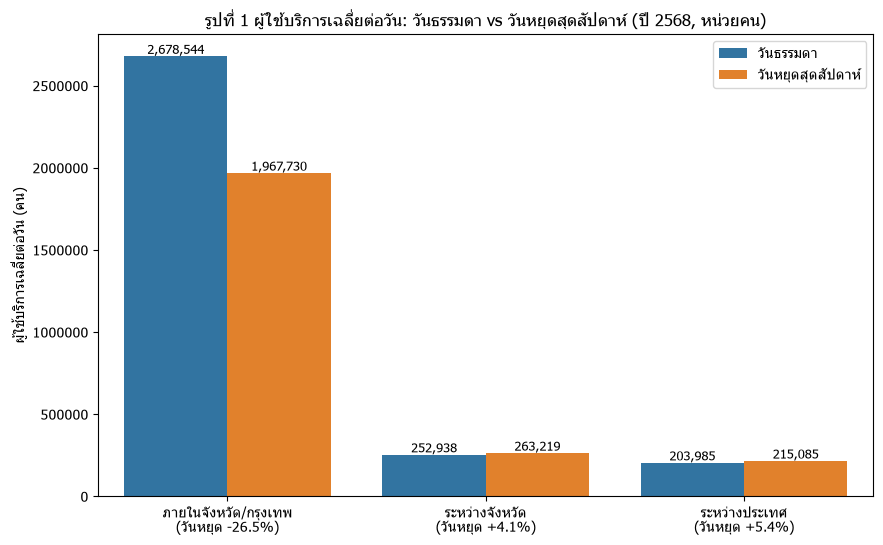

In [ ]:
# ชื่อแกน x พร้อม % ต่าง
labels = []
for p in order:
    v = diff.loc[diff["วัตถุประสงค์"] == p, "pct_diff"].iloc[0]
    labels.append(p.replace("การเดินทาง", "") + f"\n(วันหยุด {v:+.1f}%)")

plt.figure(figsize= (10, 6))
ax = sns.barplot(data= purpose, x= "วัตถุประสงค์", y= "avg_daily", hue= "day_type", order= order)
for c in ax.containers:
    ax.bar_label(c, fmt= "{:,.0f}", fontsize= 9)        # ตัวเลขบนแท่ง
ax.set_xticks(range(3))
ax.set_xticklabels(labels)
plt.ticklabel_format(style= "plain", axis= "y")          # ไม่ให้แกนแสดงเป็น 1e6
plt.title("รูปที่ 1 ผู้ใช้บริการเฉลี่ยต่อวัน: วันธรรมดา vs วันหยุดสุดสัปดาห์ (ปี 2568, หน่วยคน)")
plt.xlabel("")
plt.ylabel("ผู้ใช้บริการเฉลี่ยต่อวัน (คน)")
plt.legend(title= "")
plt.show()

**วิธีอ่าน:** แท่งน้ำเงิน = เฉลี่ยต่อวันในวันธรรมดา, แท่งส้ม = วันหยุดสุดสัปดาห์ และวงเล็บใต้ชื่อกลุ่มคือ วันหยุดต่างจากวันธรรมดากี่ %

**ผล:**
- **ในเมือง:** วันธรรมดาเฉลี่ย 2,678,544 คน/วัน วันหยุดเหลือ 1,967,730 คน/วัน **ลดลง 26.5%** (ประมาณ 710,000 คน/วัน)
- **ระหว่างจังหวัด:** 252,938 → 263,219 คน/วัน **วันหยุดมากกว่า 4.1%**
- **ระหว่างประเทศ:** 203,985 → 215,085 คน/วัน **วันหยุดมากกว่า 5.4%**
- สรุป: การเดินทางในเมืองพึ่งวันธรรมดาชัดเจน ส่วนการเดินทางระยะไกลวันหยุดสูงกว่าเล็กน้อย

## 1.2 รูปแบบตามวันในสัปดาห์ (Heatmap)

ใช้ ratio_to_median (1 = วันปกติของบริการ) จึงเทียบบริการที่ขนาดต่างกันได้ในตารางเดียว เรียงแถวตาม weekend_ratio (AIE314 บทที่ 7 หน้า 23–26)
*pivot_table ไม่พบในเอกสารวิชา ใช้เพื่อจัดตาราง บริการ × วันในสัปดาห์ สำหรับ heatmap*

In [ ]:
heat = df_q1.pivot_table(index= "ยานพาหนะ/ท่า", columns= "day_of_week",
                         values= "ratio_to_median", aggfunc= "median")
heat = heat.loc[ratio["ยานพาหนะ/ท่า"]]
heat.columns = ["จ.", "อ.", "พ.", "พฤ.", "ศ.", "ส.", "อา."]

plt.figure(figsize= (9, 14))
sns.heatmap(heat, cmap= "RdBu", center= 1, annot= True, fmt= ".2f")
plt.title("รูปที่ 2 ปริมาณแต่ละวันในสัปดาห์เทียบกับวันปกติของบริการ (ปี 2568)\nแดง > 1 สูงกว่าปกติ, น้ำเงิน < 1 ต่ำกว่าปกติ")
plt.xlabel("วันในสัปดาห์")
plt.ylabel("")
plt.show()

KeyError: "['รถหมวด 3', 'รถยนต์ทุกประเภท (ทางด่วน)', 'รถหมวด 4', 'รถยนต์ทุกประเภท (10 จุดสำรวจ)'] not in index"

In [ ]:
# รถไฟฟ้าทุกสาย: วันศุกร์ เทียบกับเสาร์-อาทิตย์
rail = heat.index.str.contains("รถไฟฟ้า", regex= False)
display(heat.loc[rail, ["พ.", "พฤ.", "ศ.", "ส.", "อา."]].round(2))

# บริการที่เป็นตัวอย่างพิเศษ
display(heat.loc[["เรือคลองแสนแสบ", "รถหมวด 3", "ท่าอากาศยานสุวรรณภูมิ"]].round(2))

,พ.,พฤ.,ศ.,ส.,อา.
ยานพาหนะ/ท่า,,,,,
รถไฟฟ้าสายสีม่วง,1.05,1.04,1.05,0.61,0.50
รถไฟฟ้าสายสีน้ำเงิน,1.03,1.04,1.07,0.70,0.58
รถไฟฟ้าสายสีชมพู,1.05,1.03,1.12,0.75,0.60
รถไฟฟ้าสายสีแดง,1.02,1.02,1.12,0.73,0.67
รถไฟฟ้า BTS,1.04,1.04,1.09,0.76,0.65
รถไฟฟ้าสายสีเหลือง,1.04,1.04,1.10,0.79,0.67
รถไฟฟ้า ARL,1.03,1.04,1.10,0.79,0.70


,จ.,อ.,พ.,พฤ.,ศ.,ส.,อา.
ยานพาหนะ/ท่า,,,,,,,
เรือคลองแสนแสบ,1.00,1.00,1.01,1.01,1.00,0.33,0.33
รถหมวด 3,0.87,0.89,1.01,1.12,1.13,1.11,0.37
ท่าอากาศยานสุวรรณภูมิ,0.95,0.94,0.95,0.99,1.00,1.00,0.98


**วิธีอ่าน:** แต่ละช่อง = ปริมาณวันนั้นเทียบกับวันปกติของบริการ (1.00 = ปกติ) แถวเรียงตามรูปที่ 1 กลุ่มวันทำงานสูงกว่าอยู่บนสุด

**ผล:**
- **กลุ่มบน (ในเมือง):** จันทร์–ศุกร์ประมาณ 1.00–1.12 แล้วลดลงเสาร์-อาทิตย์ เช่น เรือคลองแสนแสบ จ.–ศ. 1.00–1.01 แต่ ส./อา. เหลือ **0.33 / 0.33**
- **รถไฟฟ้า 7 สาย:** วันศุกร์สูงสุดของสัปดาห์ (หรือเท่ากับวันสูงสุด) อยู่ที่ **1.05–1.12** ส่วนวันอาทิตย์ต่ำสุด **0.50–0.70** (สายสีม่วงต่ำสุด 0.50)
- **รถหมวด 3** ต่างจากบริการอื่น: วันเสาร์ **1.11** แต่วันอาทิตย์ **0.37**
- **กลุ่มกลาง (ท่าอากาศยาน, บขส.):** สีอ่อนเกือบทั้งแถว แต่ละวันไม่ต่างจากปกติมาก เช่น สุวรรณภูมิ 0.94–1.00

## 1.3 รูปแบบตามเดือน

weekend_ratio รายเดือน = มัธยฐาน ratio_to_median วันหยุด ÷ วันทำงาน ของแต่ละกลุ่มในเดือนนั้น ใช้ดูว่าช่องว่างวันทำงาน/วันหยุดเปลี่ยนไปตามเดือนหรือไม่ (AIE314 บทที่ 7 หน้า 11–13)

,min,max
pattern,,
วันทำงานสูงกว่า,0.645,0.707
ใกล้เคียงกัน,1.019,1.073
วันหยุดสูงกว่า,1.065,1.326


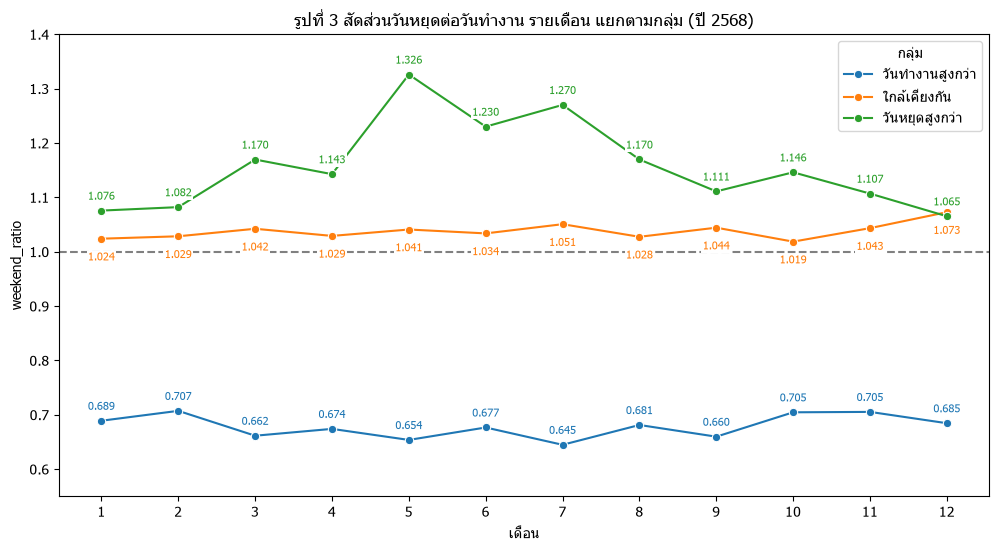

In [ ]:
# ติดกลุ่มรูปแบบให้ทุกแถว
df_q1 = pd.merge(df_q1, ratio[["ยานพาหนะ/ท่า", "pattern"]], on= "ยานพาหนะ/ท่า",
                 how= "left", validate= "many_to_one")

# มัธยฐาน ratio_to_median ราย กลุ่ม × เดือน × ประเภทวัน
monthly = df_q1.groupby(["pattern", "month", "is_weekend"], as_index= False, observed= True).agg(
    median_ratio= ("ratio_to_median", "median"))
wd = monthly[monthly["is_weekend"] == 0][["pattern", "month", "median_ratio"]]
we = monthly[monthly["is_weekend"] == 1][["pattern", "month", "median_ratio"]]

# median_ratio_x = วันทำงาน, median_ratio_y = วันหยุด
monthly_ratio = pd.merge(wd, we, on= ["pattern", "month"], how= "inner", validate= "one_to_one")
monthly_ratio["weekend_ratio"] = monthly_ratio["median_ratio_y"] / monthly_ratio["median_ratio_x"]

display(monthly_ratio.groupby("pattern", observed= True)["weekend_ratio"].agg(["min", "max"]).round(3))

plt.figure(figsize= (12, 6))
sns.lineplot(data= monthly_ratio, x= "month", y= "weekend_ratio", hue= "pattern", marker= "o")
plt.axhline(1, color= "gray", linestyle= "--")      # 1 = วันหยุดเท่ากับวันทำงาน

# ใส่ตัวเลขทุกจุด: กลุ่มกลางวางไว้ใต้จุด เพื่อไม่ให้ชนกับกลุ่มบน
offset = {"วันทำงานสูงกว่า": 0.02, "ใกล้เคียงกัน": -0.04, "วันหยุดสูงกว่า": 0.02}
color = {"วันทำงานสูงกว่า": "C0", "ใกล้เคียงกัน": "C1", "วันหยุดสูงกว่า": "C2"}   # สีเดียวกับเส้น

for i in monthly_ratio.index:
    m = monthly_ratio.loc[i, "month"]
    v = monthly_ratio.loc[i, "weekend_ratio"]
    p = monthly_ratio.loc[i, "pattern"]
    plt.text(m, v + offset[p], f"{v:.3f}", ha= "center", fontsize= 8, color= color[p],
             bbox= dict(facecolor= "white", edgecolor= "none", pad= 1))

plt.xticks(range(1, 13))
plt.ylim(0.55, 1.4)
plt.title("รูปที่ 3 สัดส่วนวันหยุดต่อวันทำงาน รายเดือน แยกตามกลุ่ม (ปี 2568)")
plt.xlabel("เดือน")
plt.ylabel("weekend_ratio")
plt.legend(title= "กลุ่ม")
plt.show()

In [ ]:
# เดือนที่ต่ำสุดและสูงสุดของแต่ละกลุ่ม
for name in ["วันทำงานสูงกว่า", "ใกล้เคียงกัน", "วันหยุดสูงกว่า"]:
    g = monthly_ratio[monthly_ratio["pattern"] == name].sort_values("weekend_ratio")
    print(name, "| ต่ำสุด: เดือน", g["month"].iloc[0], "=", round(g["weekend_ratio"].iloc[0], 3),
          "| สูงสุด: เดือน", g["month"].iloc[-1], "=", round(g["weekend_ratio"].iloc[-1], 3))

วันทำงานสูงกว่า | ต่ำสุด: เดือน 7 = 0.645 | สูงสุด: เดือน 2 = 0.707
ใกล้เคียงกัน | ต่ำสุด: เดือน 10 = 1.019 | สูงสุด: เดือน 12 = 1.073
วันหยุดสูงกว่า | ต่ำสุด: เดือน 12 = 1.065 | สูงสุด: เดือน 5 = 1.326


**วิธีอ่าน:** แต่ละจุด = สัดส่วนวันหยุด ÷ วันทำงานของกลุ่มนั้นในเดือนนั้น ถ้าเส้นเรียบแปลว่าช่องว่างวันทำงาน/วันหยุดคงที่ทั้งปี

**ผล:**
- **วันทำงานสูงกว่า:** เส้นแทบราบ อยู่ระหว่าง **0.645 (ก.ค.) – 0.707 (ก.พ.)** วันหยุดมีคนประมาณ 65–71% ของวันทำงานทุกเดือน
- **ใกล้เคียงกัน:** อยู่ระหว่าง **1.019 (ต.ค.) – 1.073 (ธ.ค.)** ใกล้เส้น 1 ตลอดปี
- **วันหยุดสูงกว่า:** เปลี่ยนมากที่สุด สูงสุด **พ.ค. 1.326** รองลงมาคือ ก.ค. 1.270 และ มิ.ย. 1.230 ต่ำสุด **ธ.ค. 1.065**